# Baseline – Betrugserkennung bei Strom und Gas
**Team 5 (Roland, Leo, Tobias)** · Meilenstein 2

Eine Baseline ist das Einfachste, das funktionieren könnte. Sie gibt uns einen Wert, den die besseren Modelle später schlagen müssen.

Daten: `data/fd_cleaned.csv` (aus `04_eda.ipynb`) · Split: `data/fd_split.csv` · Bewertung: `fd_utils.py`

| # | Schritt |
|---|---|
| 1 | Setup |
| 2 | Daten laden |
| 3 | Train und Test trennen |
| 4 | Baseline 1: immer "kein Betrug" |
| 5 | Baseline 2: einfache Regel aus der EDA |
| 6 | Baseline 3: logistische Regression |
| 7 | Vergleich |
| 8 | Baseline speichern |

## 1 · Setup

In [2]:
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score, roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

from fd_utils import RANDOM_STATE, evaluate_cv

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

DATA_DIR = Path("data")
MODEL_DIR = Path("models")

## 2 · Daten laden
`fd_cleaned.csv` liegt nicht auf GitHub. Wer die Datei noch nicht hat, führt einmal `04_eda.ipynb` komplett aus.

In [3]:
df = pd.read_csv(DATA_DIR / "fd_cleaned.csv", parse_dates=["creation_date"])
df_split = pd.read_csv(DATA_DIR / "fd_split.csv")

# Split an die Kunden hängen
df = df.merge(df_split, on="client_id", how="left")

print("Kunden:", df.shape)
print("Kunden ohne Split:", df["split"].isna().sum())
df.groupby("split")["target"].agg(["count", "mean"]).round(4)

Kunden: (135493, 21)
Kunden ohne Split: 0


,count,mean
split,,
test,27099,0.0558
train,108394,0.0558


## 3 · Train und Test trennen
`client_id` und `creation_date` sind keine Features (`contract_age_years` enthält das Datum schon als Zahl). `split` brauchen wir nur zum Trennen.

**Den Test-Teil benutzen wir hier nicht.** Alle Bewertungen laufen mit Cross-Validation auf dem Train-Teil (5 Folds, siehe `fd_utils.py`). Der Test-Teil kommt erst in `09_final.ipynb` dran.

In [4]:
df_train = df[df["split"] == "train"]
df_test = df[df["split"] == "test"]

nicht_features = ["client_id", "creation_date", "split", "target"]

X_train = df_train.drop(columns=nicht_features)
y_train = df_train["target"]
X_test = df_test.drop(columns=nicht_features)
y_test = df_test["target"]

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
X_train.head()

X_train: (108394, 17) | X_test: (27099, 17)


,disrict,client_catg,region,n_invoices,n_counters,share_gas,share_zero,any_index_backwards,share_statue_not_ok,cons_median_elec,cons_mean_elec,cons_std_elec,cons_median_gaz,cons_mean_gaz,cons_std_gaz,contract_age_years,active_years
0,60,11,101,35,1,0.0,0.0,0,0.0,267.0,362.971429,341.553930,0.0,0.0,0.0,24.933607,13.418207
1,69,11,107,37,1,0.0,0.0,0,0.0,520.0,557.540541,197.935960,0.0,0.0,0.0,17.524983,13.451061
2,62,11,301,18,1,0.0,0.0,0,0.0,655.5,836.500000,646.808386,0.0,0.0,0.0,33.735797,13.472964
3,69,11,105,20,1,0.0,0.8,0,0.0,0.0,1.200000,3.607011,0.0,0.0,0.0,23.405886,7.293634
4,62,11,303,14,1,0.0,0.0,0,0.0,770.0,922.642857,633.485669,0.0,0.0,0.0,5.147159,4.339493


## 4 · Baseline 1: immer "kein Betrug"
Das dümmste mögliche Modell: Es sagt immer die häufigste Klasse vorher.

In [5]:
dummy = DummyClassifier(strategy="most_frequent")

ergebnisse = evaluate_cv(dummy, X_train, y_train, "Immer kein Betrug")
ergebnisse

,ROC-AUC,ROC-AUC std,Recall,Precision
Immer kein Betrug,0.5,0.0,0.0,0.0


ROC-AUC 0,5 = reiner Zufall, Recall 0 = kein einziger Betrüger gefunden. Alles, was wir bauen, muss deutlich darüber liegen.

## 5 · Baseline 2: einfache Regel aus der EDA
In der EDA war die **Anzahl der Zähler** das stärkste Merkmal (1 Zähler: 2 % Betrug, 4 Zähler: 20 %). Unsere Regel: **Je mehr Zähler, desto verdächtiger.**

Die Regel wird nicht trainiert, deshalb brauchen wir hier keine Cross-Validation. Wir nehmen `n_counters` direkt als "Verdachts-Wert".

In [6]:
# ROC-AUC: Wie gut sortiert die Anzahl der Zähler Betrüger nach oben?
auc_regel = roc_auc_score(y_train, X_train["n_counters"])

# Recall und Precision für die Regel "ab 3 Zählern = Betrug"
y_regel = (X_train["n_counters"] >= 3).astype(int)

regel = pd.DataFrame({
    "ROC-AUC": [auc_regel],
    "ROC-AUC std": [np.nan],
    "Recall": [recall_score(y_train, y_regel)],
    "Precision": [precision_score(y_train, y_regel)],
}, index=["Regel: Anzahl Zähler"]).round(3)

ergebnisse = pd.concat([ergebnisse, regel])
ergebnisse

,ROC-AUC,ROC-AUC std,Recall,Precision
Immer kein Betrug,0.500,0.0,0.000,0.000
Regel: Anzahl Zähler,0.707,NaN,0.388,0.156


**Was fällt auf?**
* Die Regel erreicht schon eine ROC-AUC von **0,71**, ganz ohne Training.
* "Ab 3 Zählern = Betrug" findet 39 % der Betrüger. Von den Verdachtsfällen sind 16 % wirklich Betrug (statt 5,6 % bei Zufall).

## 6 · Baseline 3: logistische Regression
Wie im EDA-Fazit geplant, erst mit **wenigen Features**, dann mit **allen Spalten** aus `fd_cleaned.csv`.

Vorbereitung in einer Pipeline (wie in week06), damit sie in jedem Fold nur auf den Trainingsdaten gelernt wird:
* **Kategorien** (`disrict`, `client_catg`, `region`): One-Hot-Encoding. Regionen mit weniger als 100 Kunden werden zu einer Gruppe zusammengefasst (`min_frequency=100`).
* **Verbrauch**: erst `log(1 + x)`, weil er so schief verteilt ist (EDA, 7.3), dann skalieren.
* **Andere Zahlen**: skalieren.
* `class_weight="balanced"`, weil es so wenig Betrug gibt.

In [7]:
kategorien = ["disrict", "client_catg", "region"]


def make_logreg(verbrauch, zahlen):
    # Pipeline: Vorbereitung + logistische Regression
    vorbereitung = ColumnTransformer([
        ("kategorien", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=100), kategorien),
        ("verbrauch", Pipeline([("log", FunctionTransformer(np.log1p)), ("scaler", StandardScaler())]), verbrauch),
        ("zahlen", StandardScaler(), zahlen),
    ])
    return Pipeline([
        ("vorbereitung", vorbereitung),
        ("logreg", LogisticRegression(class_weight="balanced", max_iter=1000)),
    ])

### 6.1 Wenige Features (wie im EDA-Fazit)

In [8]:
logreg_klein = make_logreg(
    verbrauch=["cons_median_elec", "cons_median_gaz"],
    zahlen=["contract_age_years"],
)

ergebnisse = pd.concat([ergebnisse, evaluate_cv(logreg_klein, X_train, y_train, "LogReg: wenige Features")])
ergebnisse

,ROC-AUC,ROC-AUC std,Recall,Precision
Immer kein Betrug,0.500,0.000,0.000,0.000
Regel: Anzahl Zähler,0.707,NaN,0.388,0.156
LogReg: wenige Features,0.663,0.004,0.632,0.087


### 6.2 Alle Spalten aus `fd_cleaned.csv`

In [9]:
verbrauch_spalten = ["cons_median_elec", "cons_mean_elec", "cons_std_elec",
                     "cons_median_gaz", "cons_mean_gaz", "cons_std_gaz"]
zahlen_spalten = ["n_invoices", "n_counters", "share_gas", "share_zero", "any_index_backwards",
                  "share_statue_not_ok", "contract_age_years", "active_years"]

logreg_alle = make_logreg(verbrauch=verbrauch_spalten, zahlen=zahlen_spalten)

ergebnisse = pd.concat([ergebnisse, evaluate_cv(logreg_alle, X_train, y_train, "LogReg: alle Spalten")])
ergebnisse

,ROC-AUC,ROC-AUC std,Recall,Precision
Immer kein Betrug,0.500,0.000,0.000,0.000
Regel: Anzahl Zähler,0.707,NaN,0.388,0.156
LogReg: wenige Features,0.663,0.004,0.632,0.087
LogReg: alle Spalten,0.804,0.007,0.743,0.142


## 7 · Vergleich

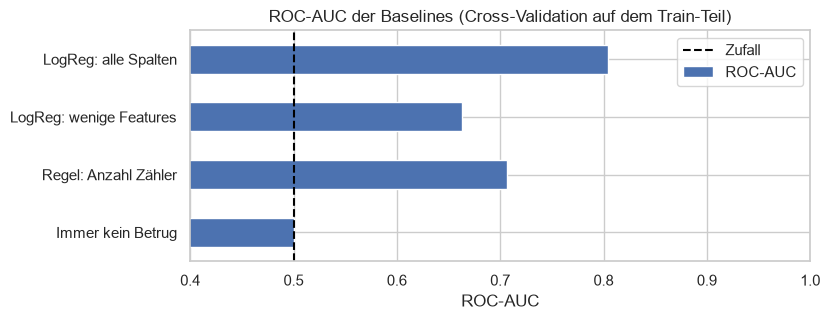

,ROC-AUC,ROC-AUC std,Recall,Precision
Immer kein Betrug,0.500,0.000,0.000,0.000
Regel: Anzahl Zähler,0.707,NaN,0.388,0.156
LogReg: wenige Features,0.663,0.004,0.632,0.087
LogReg: alle Spalten,0.804,0.007,0.743,0.142


In [10]:
ergebnisse["ROC-AUC"].plot(kind="barh", figsize=(8, 3))
plt.axvline(0.5, color="black", linestyle="--", label="Zufall")
plt.title("ROC-AUC der Baselines (Cross-Validation auf dem Train-Teil)")
plt.xlabel("ROC-AUC")
plt.xlim(0.4, 1)
plt.legend()
plt.show()

ergebnisse

**Was fällt auf?**
* Die logistische Regression mit **wenigen Features** (0,66) ist sogar **schlechter als die einfache Regel** (0,71). Die Anzahl der Zähler fehlt ihr, und genau die ist das stärkste Merkmal.
* Mit **allen Spalten** aus `fd_cleaned.csv` kommt sie auf **0,80**. Das ist unsere Baseline.
* Recall (74 %) und Precision (14 %) gelten für die Schwelle 0,5. Durch `class_weight="balanced"` sagt das Modell oft "Betrug", findet also viele Betrüger, hat aber viele falsche Alarme. Welche Schwelle sinnvoll ist, schauen wir in `08_fehleranalyse.ipynb` an.

## 8 · Baseline speichern
Wir trainieren die logistische Regression mit allen Spalten einmal auf dem ganzen Train-Teil und speichern sie. `09_final.ipynb` vergleicht sie am Ende auf dem Test-Teil mit dem besten Modell.

Die Modelldateien landen in `models/` und werden wegen `.gitignore` nicht hochgeladen.

In [11]:
logreg_alle.fit(X_train, y_train)

MODEL_DIR.mkdir(exist_ok=True)
joblib.dump(logreg_alle, MODEL_DIR / "fd_baseline.joblib")
print("Gespeichert: models/fd_baseline.joblib")

Gespeichert: models/fd_baseline.joblib


## Fazit

| Modell | ROC-AUC (CV) |
|---|---|
| Immer kein Betrug | 0,50 |
| Regel: Anzahl Zähler | 0,71 |
| LogReg: wenige Features | 0,66 |
| **LogReg: alle Spalten (Baseline)** | **0,80** |

**Diesen Wert (0,80) müssen die Modelle in `07_modelle.ipynb` schlagen.**